### Validação fora da amostra do modelo de risco de encerramento

**Entrada:** `data/df_modelo_treino.parquet` (45.874 linhas, 7 preditores + `alvo`), gerado pelo notebook 05. Como esse arquivo não traz `cnpj_basico`, a coluna é lida de `data/dataset_modelagem_final.parquet` (mesma ordem de linhas, conferida por `assert` abaixo).

**Escopo:** divisão treino/teste agrupada por empresa, métricas fora da amostra (AUC, Gini, KS), validação cruzada, baselines, calibração, sensibilidade à categoria `2062` e coeficientes padronizados.

**Limite que não dá para contornar:** só existe uma extração (08/08/2026). Validação **fora do tempo** não é possível, e este notebook não a simula. Todos os preditores e o desfecho vêm da mesma fotografia de 2026.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
CUTOFF = 0.5  # mesmo ponto de corte padrão do notebook 05

In [2]:
df = pd.read_parquet('../data/df_modelo_treino.parquet')
ids = pd.read_parquet('../data/dataset_modelagem_final.parquet', columns=['cnpj_basico', 'identificador_matriz_filial', 'alvo_baixada', 'capital_social'])

# o treino do notebook 05 foi montado por seleção de colunas, sem reordenar linhas; confere o alinhamento antes de herdar o cnpj_basico
assert len(df) == len(ids)
assert (df['identificador_matriz_filial'].astype(str).values == ids['identificador_matriz_filial'].astype(str).values).all()
assert (df['alvo'].values == ids['alvo_baixada'].values).all()
assert np.allclose(df['capital_social_log'].values, np.log1p(ids['capital_social'].values))
df['cnpj_basico'] = ids['cnpj_basico'].values

print(df.shape)
print(df['alvo'].value_counts(normalize=True).rename('proporção'))

(45874, 9)
alvo
1    0.590269
0    0.409731
Name: proporção, dtype: float64


#### 1. Repetição de `cnpj_basico` (matriz e filiais da mesma empresa)

Um mesmo `cnpj_basico` com mais de uma linha viola a independência entre observações e, numa divisão aleatória simples, poria a mesma empresa nos dois lados.

In [3]:
tam_grupo = df.groupby('cnpj_basico').size()
repetidos = tam_grupo[tam_grupo > 1]

print('Linhas:', len(df))
print('cnpj_basico únicos:', df['cnpj_basico'].nunique())
print('cnpj_basico com mais de uma linha:', len(repetidos))
print('Linhas que pertencem a um cnpj_basico repetido:', int(repetidos.sum()))
print('Linhas "excedentes" (linhas - únicos):', len(df) - df['cnpj_basico'].nunique())
print('Tamanho do maior grupo:', int(tam_grupo.max()))
print('\nDistribuição do tamanho dos grupos:')
print(tam_grupo.value_counts().sort_index().to_string())

rep = df[df['cnpj_basico'].isin(repetidos.index)]
print('\nLinhas repetidas por tipo (1=matriz, 2=filial):')
print(rep['identificador_matriz_filial'].value_counts().to_string())
print('\nTaxa de evento nas linhas repetidas:', round(rep['alvo'].mean(), 4), '| nas demais:', round(df.loc[~df.index.isin(rep.index), 'alvo'].mean(), 4))

Linhas: 45874
cnpj_basico únicos: 45610
cnpj_basico com mais de uma linha: 142
Linhas que pertencem a um cnpj_basico repetido: 406
Linhas "excedentes" (linhas - únicos): 264
Tamanho do maior grupo: 17

Distribuição do tamanho dos grupos:
1     45468
2       107
3        13
4         7
5         1
6         5
7         3
8         1
9         1
10        2
15        1
17        1

Linhas repetidas por tipo (1=matriz, 2=filial):
identificador_matriz_filial
2    397
1      9

Taxa de evento nas linhas repetidas: 0.3793 | nas demais: 0.5922


#### 2. Divisão treino (70%) / teste (30%), estratificada por `alvo` e agrupada por `cnpj_basico`

Há `cnpj_basico` repetido (seção 1), então a divisão é por grupo. Usa-se `StratifiedGroupKFold` com 10 partes e semente fixa; 3 partes formam o teste (~30%), e as outras 7, o treino. Nenhuma empresa aparece nos dois lados.

In [4]:
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
partes = list(sgkf.split(df, df['alvo'], groups=df['cnpj_basico']))

idx_teste = np.concatenate([p[1] for p in partes[:3]])
mask_teste = np.zeros(len(df), dtype=bool)
mask_teste[idx_teste] = True

df_treino = df.loc[~mask_teste].reset_index(drop=True)
df_teste = df.loc[mask_teste].reset_index(drop=True)

inter = set(df_treino['cnpj_basico']) & set(df_teste['cnpj_basico'])
assert len(inter) == 0, 'empresa nos dois lados'

print(f'Treino: {len(df_treino)} ({len(df_treino)/len(df):.1%}) | taxa de evento {df_treino["alvo"].mean():.4f}')
print(f'Teste:  {len(df_teste)} ({len(df_teste)/len(df):.1%}) | taxa de evento {df_teste["alvo"].mean():.4f}')
print('cnpj_basico nos dois lados:', len(inter))

Treino: 32110 (70.0%) | taxa de evento 0.5930
Teste:  13764 (30.0%) | taxa de evento 0.5840
cnpj_basico nos dois lados: 0


#### 3. Stepwise e ajuste só no treino; AUC, Gini e KS no treino e no teste

A codificação em dummies repete a do notebook 05 (categoria de referência = a mais frequente; `drop_first=True`). A função `stepwise_manual` é copiada sem alterações do notebook 05 (célula 17).

In [5]:
ordem_categorias = {
    'identificador_matriz_filial': ['1', '2'],
    'porte_empresa': ['01', '03', '05'],
    'natureza_juridica_agrupada': ['2135', '2062', '2054', '2046', 'Outras'],
    'regiao': ['Sudeste', 'Nordeste', 'Sul', 'Centro-Oeste', 'Norte'],
    'grupo_cnae': ['478', '472', '475', '471', '477', '474', '476', '473'],
}
PREDITORES = ['identificador_matriz_filial', 'idade_empresa_anos', 'capital_social_log', 'porte_empresa',
              'natureza_juridica_agrupada', 'regiao', 'grupo_cnae']

def dummizar(d):
    # mesma codificação do notebook 05 (células 12-13), sem o cnpj_basico
    d = d[PREDITORES + ['alvo']].copy()
    for col, ordem in ordem_categorias.items():
        d[col] = pd.Categorical(d[col].astype(str), categories=ordem, ordered=False)
    out = pd.get_dummies(d, columns=list(ordem_categorias.keys()), drop_first=True, dtype=int)
    out.columns = out.columns.str.replace('-', '_', regex=False)
    return out

dum_treino = dummizar(df_treino)
dum_teste = dummizar(df_teste)
assert list(dum_treino.columns) == list(dum_teste.columns)

preditores_dummies = [c for c in dum_treino.columns if c != 'alvo']
formula_completa = 'alvo ~ ' + ' + '.join(preditores_dummies)
print(len(preditores_dummies), 'termos antes do stepwise')

20 termos antes do stepwise


In [6]:
# Stepwise manual (backward elimination por teste de Wald) -- copiado sem alterações do notebook 05, célula 17.
def stepwise_manual(formula_base, data, pvalue_limit=0.05, verbose=True):
    formula_atual = formula_base
    while True:
        modelo = sm.Logit.from_formula(formula_atual, data=data).fit(disp=0)
        pvalues = modelo.pvalues.drop('Intercept')
        pior_pvalue = pvalues.max()

        if pior_pvalue <= pvalue_limit:
            break

        variavel_remover = pvalues.idxmax()
        if verbose:
            print(f"Removendo '{variavel_remover}' (p-valor = {pior_pvalue:.4f})")

        preditores_restantes = [v for v in pvalues.index if v != variavel_remover]
        formula_atual = 'alvo ~ ' + ' + '.join(preditores_restantes)

    return modelo, formula_atual

modelo_val, formula_val = stepwise_manual(formula_completa, dum_treino, pvalue_limit=0.05)
print('\nFórmula final (ajustada só no treino):')
print(formula_val)
print(modelo_val.summary())

Removendo 'regiao_Norte' (p-valor = 0.1370)
Removendo 'regiao_Nordeste' (p-valor = 0.1660)
Removendo 'grupo_cnae_472' (p-valor = 0.1254)

Fórmula final (ajustada só no treino):
alvo ~ idade_empresa_anos + capital_social_log + identificador_matriz_filial_2 + porte_empresa_03 + porte_empresa_05 + natureza_juridica_agrupada_2062 + natureza_juridica_agrupada_2054 + natureza_juridica_agrupada_2046 + natureza_juridica_agrupada_Outras + regiao_Sul + regiao_Centro_Oeste + grupo_cnae_475 + grupo_cnae_471 + grupo_cnae_477 + grupo_cnae_474 + grupo_cnae_476 + grupo_cnae_473
                           Logit Regression Results                           
Dep. Variable:                   alvo   No. Observations:                32110
Model:                          Logit   Df Residuals:                    32092
Method:                           MLE   Df Model:                           17
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                 0.06096
Time:                        10:33:0

In [7]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def metricas(y, p):
    auc = roc_auc_score(y, p)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(y, p)}

p_treino = modelo_val.predict(dum_treino)
p_teste = modelo_val.predict(dum_teste)

tab = pd.DataFrame({
    'treino': metricas(dum_treino['alvo'], p_treino),
    'teste': metricas(dum_teste['alvo'], p_teste),
}).T
tab['n'] = [len(dum_treino), len(dum_teste)]
print(tab.round(4).to_string())
print('\nQueda do AUC treino -> teste:', round(tab.loc['treino', 'AUC'] - tab.loc['teste', 'AUC'], 4))

# referência: o notebook 05 reportou AUC 0,6521 / Gini 0,3042 na base inteira, dentro da amostra

           AUC   Gini      KS      n
treino  0.6510  0.302  0.2223  32110
teste   0.6545  0.309  0.2342  13764

Queda do AUC treino -> teste: -0.0035


#### 4. Validação cruzada de 5 folds (agrupada por `cnpj_basico`, estratificada por `alvo`)

Feita só sobre o treino, para não tocar no teste. O stepwise é refeito **dentro de cada fold**, para que a seleção de variáveis também fique fora da amostra de avaliação.

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
aucs = []
for k, (i_tr, i_va) in enumerate(cv.split(dum_treino, dum_treino['alvo'], groups=df_treino['cnpj_basico']), start=1):
    tr, va = dum_treino.iloc[i_tr], dum_treino.iloc[i_va]
    m, f = stepwise_manual(formula_completa, tr, pvalue_limit=0.05, verbose=False)
    auc_va = roc_auc_score(va['alvo'], m.predict(va))
    auc_tr = roc_auc_score(tr['alvo'], m.predict(tr))
    aucs.append(auc_va)
    print(f'fold {k}: n_treino={len(tr)} n_val={len(va)} | termos mantidos={len(m.params)-1} | AUC treino={auc_tr:.4f} | AUC validação={auc_va:.4f}')

aucs = np.array(aucs)
print(f'\nAUC de validação (5 folds): média = {aucs.mean():.4f} | desvio-padrão = {aucs.std(ddof=1):.4f} | min = {aucs.min():.4f} | max = {aucs.max():.4f}')

fold 1: n_treino=25696 n_val=6414 | termos mantidos=18 | AUC treino=0.6504 | AUC validação=0.6503
fold 2: n_treino=25679 n_val=6431 | termos mantidos=15 | AUC treino=0.6520 | AUC validação=0.6448
fold 3: n_treino=25685 n_val=6425 | termos mantidos=14 | AUC treino=0.6497 | AUC validação=0.6531
fold 4: n_treino=25682 n_val=6428 | termos mantidos=15 | AUC treino=0.6496 | AUC validação=0.6545
fold 5: n_treino=25698 n_val=6412 | termos mantidos=17 | AUC treino=0.6525 | AUC validação=0.6420

AUC de validação (5 folds): média = 0.6489 | desvio-padrão = 0.0054 | min = 0.6420 | max = 0.6545


#### 5. Baselines no teste, no mesmo ponto de corte

Dois baselines: (i) sempre prever "baixada" (equivale ao modelo só com intercepto no corte de 0,5, porque a taxa de eventos no treino passa de 0,5); (ii) o modelo só com intercepto, que dá o mesmo escore a todos, com AUC igual a 0,5 por construção. A precisão e a acurácia do modelo são medidas nos mesmos cortes.

In [9]:
y_te = dum_teste['alvo'].values

modelo_nulo = sm.Logit.from_formula('alvo ~ 1', data=dum_treino).fit(disp=0)
p_nulo = modelo_nulo.predict(dum_teste)
print('Modelo só com intercepto: probabilidade constante =', round(float(p_nulo.iloc[0]), 4))
print('AUC do modelo só com intercepto no teste:', round(roc_auc_score(y_te, p_nulo), 4))
print('AUC do modelo completo no teste:        ', round(roc_auc_score(y_te, p_teste), 4))

def avalia_corte(y, p, corte):
    pred = (np.asarray(p) >= corte).astype(int)
    vp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    vn = int(((pred == 0) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    return {
        'prevê baixada (%)': 100 * pred.mean(),
        'acurácia': (vp + vn) / len(y),
        'precisão': vp / (vp + fp) if (vp + fp) else np.nan,
        'sensitividade': vp / (vp + fn),
        'especificidade': vn / (vn + fp) if (vn + fp) else np.nan,
    }

taxa_teste = y_te.mean()
linhas = {}
for corte in (CUTOFF, 0.62):
    linhas[f'modelo, corte {corte}'] = avalia_corte(y_te, p_teste, corte)
    linhas[f'só intercepto, corte {corte}'] = avalia_corte(y_te, p_nulo, corte)
linhas['sempre prever baixada'] = {'prevê baixada (%)': 100.0, 'acurácia': taxa_teste, 'precisão': taxa_teste, 'sensitividade': 1.0, 'especificidade': 0.0}
res = pd.DataFrame(linhas).T
print('\nTaxa de baixada no teste (acurácia e precisão do baseline "sempre baixada"):', round(taxa_teste, 4))
print(res.round(4).to_string())

m = res.loc[f'modelo, corte {CUTOFF}']
print(f'\nCorte {CUTOFF}: acurácia do modelo - baseline = {m["acurácia"] - taxa_teste:+.4f} | precisão do modelo - baseline = {m["precisão"] - taxa_teste:+.4f} | lift de precisão = {m["precisão"] / taxa_teste:.3f}')

Modelo só com intercepto: probabilidade constante = 0.593
AUC do modelo só com intercepto no teste: 0.5
AUC do modelo completo no teste:         0.6545

Taxa de baixada no teste (acurácia e precisão do baseline "sempre baixada"): 0.584
                           prevê baixada (%)  acurácia  precisão  sensitividade  especificidade
modelo, corte 0.5                    82.2581    0.6569    0.6464         0.9105          0.3009
só intercepto, corte 0.5            100.0000    0.5840    0.5840         1.0000          0.0000
modelo, corte 0.62                   56.6478    0.6201    0.6801         0.6597          0.5644
só intercepto, corte 0.62             0.0000    0.4160       NaN         0.0000          1.0000
sempre prever baixada               100.0000    0.5840    0.5840         1.0000          0.0000

Corte 0.5: acurácia do modelo - baseline = +0.0729 | precisão do modelo - baseline = +0.0625 | lift de precisão = 1.107


#### 6. Calibração no teste: curva de calibração e Brier score

Curva com 10 faixas de mesmo tamanho (quantis) da probabilidade prevista. O Brier do modelo é comparado ao do modelo só com intercepto (que prevê a taxa do treino para todos). Inclui também intercepto e inclinação de calibração (regressão do desfecho sobre o logit da previsão; ideal = 0 e 1).

Brier do modelo (teste):           0.2217
Brier só com intercepto (teste):   0.2430
Brier skill score vs intercepto:   0.0878

Calibração: intercepto = -0.0553 (ideal 0) | inclinação = 1.0455 (ideal 1)
Probabilidade média prevista no teste: 0.5924 | taxa observada no teste: 0.584

Faixa | prevista média | observada
      0.268          0.240
      0.427          0.408
      0.566          0.544
      0.601          0.595
      0.623          0.636
      0.641          0.624
      0.660          0.663
      0.680          0.690
      0.703          0.731
      0.755          0.709


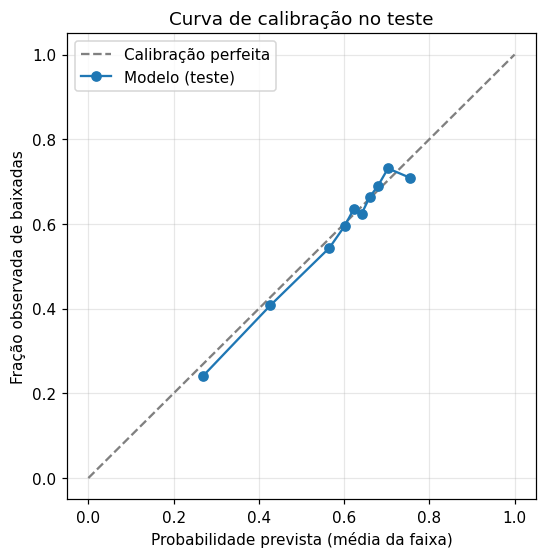

In [10]:
frac_pos, media_prev = calibration_curve(y_te, p_teste, n_bins=10, strategy='quantile')

brier_modelo = brier_score_loss(y_te, p_teste)
brier_nulo = brier_score_loss(y_te, p_nulo)
print(f'Brier do modelo (teste):           {brier_modelo:.4f}')
print(f'Brier só com intercepto (teste):   {brier_nulo:.4f}')
print(f'Brier skill score vs intercepto:   {1 - brier_modelo / brier_nulo:.4f}')

pc = np.clip(np.asarray(p_teste), 1e-6, 1 - 1e-6)
logit_p = np.log(pc / (1 - pc))
cal = sm.Logit(y_te, sm.add_constant(logit_p)).fit(disp=0)
print(f'\nCalibração: intercepto = {cal.params[0]:.4f} (ideal 0) | inclinação = {cal.params[1]:.4f} (ideal 1)')
print('Probabilidade média prevista no teste:', round(float(np.mean(p_teste)), 4), '| taxa observada no teste:', round(float(y_te.mean()), 4))

print('\nFaixa | prevista média | observada')
for a, b in zip(media_prev, frac_pos):
    print(f'      {a:.3f}          {b:.3f}')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibração perfeita')
ax.plot(media_prev, frac_pos, marker='o', label='Modelo (teste)')
ax.set_xlabel('Probabilidade prevista (média da faixa)')
ax.set_ylabel('Fração observada de baixadas')
ax.set_title('Curva de calibração no teste')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

#### 7. Sensibilidade à categoria `natureza_juridica_agrupada_2062`

O notebook 02 observa que sobreviventes da extinção da EIRELI migraram "tipicamente" para o código 2062. Para testar se essa categoria sustenta o desempenho, o modelo é reajustado de duas formas, ambas no treino e avaliadas no teste:

- **A.** retira a dummy `2062` da fórmula final (as empresas 2062 passam a compartilhar a referência 2135);
- **B.** exclui as linhas 2062 do treino e do teste e reajusta a mesma fórmula sem a dummy.

Em B o AUC do modelo completo também é recalculado sobre o mesmo subconjunto, para a comparação ser justa.

In [11]:
col_2062 = 'natureza_juridica_agrupada_2062'
termos_final = [t for t in modelo_val.params.index if t != 'Intercept']
assert col_2062 in termos_final

# A: retira só a dummy
formula_A = 'alvo ~ ' + ' + '.join(t for t in termos_final if t != col_2062)
modelo_A = sm.Logit.from_formula(formula_A, data=dum_treino).fit(disp=0)
auc_A = roc_auc_score(y_te, modelo_A.predict(dum_teste))
auc_ref = roc_auc_score(y_te, p_teste)

# B: exclui as linhas 2062
tr_B = dum_treino[dum_treino[col_2062] == 0]
te_B = dum_teste[dum_teste[col_2062] == 0]
formula_B = formula_A  # sem a dummy 2062, todas as linhas restantes têm 0 nela
modelo_B = sm.Logit.from_formula(formula_B, data=tr_B).fit(disp=0)
auc_B = roc_auc_score(te_B['alvo'], modelo_B.predict(te_B))
auc_B_ref = roc_auc_score(te_B['alvo'], modelo_val.predict(te_B))

print(f'AUC teste, modelo de referência (todas as linhas):           {auc_ref:.4f}')
print(f'AUC teste, A (sem a dummy 2062, todas as linhas):            {auc_A:.4f}  (variação {auc_A - auc_ref:+.4f})')
print(f'AUC teste, B (sem as linhas 2062), n_teste={len(te_B)}:        {auc_B:.4f}')
print(f'AUC teste, referência avaliada nas mesmas linhas de B:       {auc_B_ref:.4f}  (variação de B vs. referência: {auc_B - auc_B_ref:+.4f})')
print(f'Taxa de evento: 2062 = {df_treino.loc[df_treino["natureza_juridica_agrupada"]=="2062", "alvo"].mean():.4f} | demais = {df_treino.loc[df_treino["natureza_juridica_agrupada"]!="2062", "alvo"].mean():.4f} | linhas 2062 no treino = {(df_treino["natureza_juridica_agrupada"]=="2062").sum()}')

comp = pd.DataFrame({
    'referência': modelo_val.params,
    'A (sem dummy 2062)': modelo_A.params,
    'B (sem linhas 2062)': modelo_B.params,
})
comp['A - ref'] = comp['A (sem dummy 2062)'] - comp['referência']
comp['B - ref'] = comp['B (sem linhas 2062)'] - comp['referência']
print('\nCoeficientes:')
print(comp.round(4).to_string())

sinal = comp.dropna(subset=['A (sem dummy 2062)'])
trocas = sinal[np.sign(sinal['referência']) != np.sign(sinal['A (sem dummy 2062)'])].index.tolist()
print('\nTermos que trocam de sinal em A:', trocas if trocas else 'nenhum')
trocas_B = comp.dropna(subset=['B (sem linhas 2062)'])
trocas_B = trocas_B[np.sign(trocas_B['referência']) != np.sign(trocas_B['B (sem linhas 2062)'])].index.tolist()
print('Termos que trocam de sinal em B:', trocas_B if trocas_B else 'nenhum')

AUC teste, modelo de referência (todas as linhas):           0.6545
AUC teste, A (sem a dummy 2062, todas as linhas):            0.6370  (variação -0.0175)
AUC teste, B (sem as linhas 2062), n_teste=11256:        0.5838
AUC teste, referência avaliada nas mesmas linhas de B:       0.5822  (variação de B vs. referência: +0.0016)
Taxa de evento: 2062 = 0.3547 | demais = 0.6470 | linhas 2062 no treino = 5935

Coeficientes:
                                   referência  A (sem dummy 2062)  B (sem linhas 2062)  A - ref  B - ref
Intercept                             -0.2319              0.2853              -0.4053   0.5172  -0.1734
capital_social_log                    -0.0736             -0.1458              -0.0693  -0.0722   0.0043
grupo_cnae_471                        -0.1982             -0.1943              -0.2028   0.0039  -0.0046
grupo_cnae_473                        -0.4028             -0.5828              -0.5247  -0.1801  -0.1219
grupo_cnae_474                        -0.5404       

In [12]:
# por que o coeficiente de filial cai tanto quando as linhas 2062 saem? olha filial x natureza jurídica no treino
print('Contagem (treino):')
print(pd.crosstab(df_treino['identificador_matriz_filial'], df_treino['natureza_juridica_agrupada']).to_string())
print('\nTaxa de baixada (treino):')
print(pd.crosstab(df_treino['identificador_matriz_filial'], df_treino['natureza_juridica_agrupada'], values=df_treino['alvo'], aggfunc='mean').round(3).to_string())

Contagem (treino):
natureza_juridica_agrupada    2135  2062  2054  2046  Outras
identificador_matriz_filial                                 
1                            25755  4706     3     0       9
2                              275  1229    66    63       4

Taxa de baixada (treino):
natureza_juridica_agrupada    2135   2062   2054   2046  Outras
identificador_matriz_filial                                    
1                            0.649  0.297  0.000    NaN   0.444
2                            0.673  0.576  0.258  0.206   0.250


#### 8. Coeficientes padronizados: filial pesa mais ou menos que `capital_social_log`?

Coeficiente padronizado = coeficiente × desvio-padrão do preditor no treino (variação no logit para +1 desvio-padrão do preditor). Para dummies, o desvio-padrão é √(p(1−p)). O intervalo de confiança vem do intervalo do coeficiente bruto, escalado do mesmo modo.

In [13]:
termos = [t for t in modelo_val.params.index if t != 'Intercept']
dp = dum_treino[termos].std(ddof=0)
padr = modelo_val.params[termos] * dp
ic = modelo_val.conf_int().loc[termos]
tab_p = pd.DataFrame({
    'coef_bruto': modelo_val.params[termos],
    'desvio_padrao_x': dp,
    'coef_padronizado': padr,
    'ic95_inf': ic[0] * dp,
    'ic95_sup': ic[1] * dp,
})
tab_p['abs'] = tab_p['coef_padronizado'].abs()
print(tab_p.sort_values('abs', ascending=False).drop(columns='abs').round(4).to_string())

f = 'identificador_matriz_filial_2'
c = 'capital_social_log'
print(f'\n|padronizado| filial = {abs(padr[f]):.4f} | capital_social_log = {abs(padr[c]):.4f}')
razao = abs(padr[f]) / abs(padr[c])
print(f'Razão filial / capital = {razao:.2f}')
if abs(padr[f]) > abs(padr[c]):
    print('Filial pesa MAIS que capital_social_log em escala padronizada.')
else:
    print('Filial pesa MENOS que capital_social_log em escala padronizada.')
print('Posição de cada um entre os', len(termos), 'termos (1 = maior |efeito padronizado|):')
rank = tab_p['abs'].rank(ascending=False).astype(int)
print('  filial:', rank[f], '| capital_social_log:', rank[c], '| idade_empresa_anos:', rank['idade_empresa_anos'])
print('Filial no treino:', round(float(dum_treino[f].mean()) * 100, 2), '% das linhas (efeito grande, mas em poucos casos)')

                                   coef_bruto  desvio_padrao_x  coef_padronizado  ic95_inf  ic95_sup
natureza_juridica_agrupada_2062       -1.1341           0.3882           -0.4402   -0.4697   -0.4108
identificador_matriz_filial_2          1.2138           0.2200            0.2670    0.2378    0.2962
capital_social_log                    -0.0736           2.5411           -0.1871   -0.2173   -0.1569
idade_empresa_anos                     0.1866           0.8585            0.1602    0.1368    0.1836
grupo_cnae_474                        -0.5404           0.2456           -0.1327   -0.1565   -0.1090
natureza_juridica_agrupada_2054       -1.7601           0.0463           -0.0815   -0.1089   -0.0541
natureza_juridica_agrupada_2046       -1.7152           0.0443           -0.0759   -0.1049   -0.0469
grupo_cnae_471                        -0.1982           0.3012           -0.0597   -0.0834   -0.0360
grupo_cnae_475                        -0.1710           0.3402           -0.0582   -0.0820 

#### 9. O que este notebook não cobre

- **Validação fora do tempo:** não é possível, pois há uma única extração (08/08/2026). Treino e teste vêm da mesma fotografia; o resultado vale para empresas diferentes no mesmo período, não para períodos futuros.
- **Preditores medidos em 2026:** capital social, porte e natureza jurídica são os do cadastro atual, depois do desfecho. A validação não resolve esse limite.
- **Corte de 0,62:** foi tirado do README (equilíbrio entre sensitividade e especificidade no notebook 05, dentro da amostra), não reotimizado no teste.